 # PART 2 :  Background Subtraction

In [217]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os


video_path = r'C:\Users\Jyotirmoy Nath\Downloads\Assignment1\Assignment1\umcp.mpg'

cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise FileNotFoundError(f"Cannot open video: {video_path}")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Read all frames
frames = []
while True:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(frame)
cap.release()

print(f"Frames: {len(frames)}")
print(f"Size: {width}×{height}")
print(f"FPS: {fps:.2f}")

Frames: 999
Size: 352×240
FPS: 29.97


In [218]:
# Preprocessing
Resize_w = 160
Resize_H = 120

# Preprocess frames
preprocessed_frames = []

for i, frame in enumerate(frames):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    
    resized = cv2.resize(gray, (Resize_w, Resize_H))
    
    # Convert to float
    preprocessed = resized.astype(np.float32)
    
    preprocessed_frames.append(preprocessed)
    
    if (i+1) % 10 == 0:
        print(f"Preprocessed {i+1}/{len(frames)} frames")

Preprocessed 10/999 frames
Preprocessed 20/999 frames
Preprocessed 30/999 frames
Preprocessed 40/999 frames
Preprocessed 50/999 frames
Preprocessed 60/999 frames
Preprocessed 70/999 frames
Preprocessed 80/999 frames
Preprocessed 90/999 frames
Preprocessed 100/999 frames
Preprocessed 110/999 frames
Preprocessed 120/999 frames
Preprocessed 130/999 frames
Preprocessed 140/999 frames
Preprocessed 150/999 frames
Preprocessed 160/999 frames
Preprocessed 170/999 frames
Preprocessed 180/999 frames
Preprocessed 190/999 frames
Preprocessed 200/999 frames
Preprocessed 210/999 frames
Preprocessed 220/999 frames
Preprocessed 230/999 frames
Preprocessed 240/999 frames
Preprocessed 250/999 frames
Preprocessed 260/999 frames
Preprocessed 270/999 frames
Preprocessed 280/999 frames
Preprocessed 290/999 frames
Preprocessed 300/999 frames
Preprocessed 310/999 frames
Preprocessed 320/999 frames
Preprocessed 330/999 frames
Preprocessed 340/999 frames
Preprocessed 350/999 frames
Preprocessed 360/999 frames
P

In [219]:
# Motion Estimation
motion_frames = []
for t in range(1, len(preprocessed_frames)):
    # D_t = |F_t - F_{t-1}|
    diff = np.abs(preprocessed_frames[t] - preprocessed_frames[t-1])
    motion_frames.append(diff)
    
    if t % 10 == 0:
        print(f"Computed motion for frame {t}/{len(preprocessed_frames)}")
print(f"Shape: {motion_frames[0].shape}")

Computed motion for frame 10/999
Computed motion for frame 20/999
Computed motion for frame 30/999
Computed motion for frame 40/999
Computed motion for frame 50/999
Computed motion for frame 60/999
Computed motion for frame 70/999
Computed motion for frame 80/999
Computed motion for frame 90/999
Computed motion for frame 100/999
Computed motion for frame 110/999
Computed motion for frame 120/999
Computed motion for frame 130/999
Computed motion for frame 140/999
Computed motion for frame 150/999
Computed motion for frame 160/999
Computed motion for frame 170/999
Computed motion for frame 180/999
Computed motion for frame 190/999
Computed motion for frame 200/999
Computed motion for frame 210/999
Computed motion for frame 220/999
Computed motion for frame 230/999
Computed motion for frame 240/999
Computed motion for frame 250/999
Computed motion for frame 260/999
Computed motion for frame 270/999
Computed motion for frame 280/999
Computed motion for frame 290/999
Computed motion for fra

In [ ]:
# Sequential Labeling Algorithm for Foreground

def sequential_labeling_segmentation(motion_images, threshold=50, min_area=50):

    print(f"Threshold (τ): {threshold}")
    print(f"Min blob area: {min_area} pixels")
    
    masks = []
    
    for t, motion in enumerate(motion_images):
        # Threshold
        binary_mask = (motion > threshold).astype(np.uint8) * 255
        
        # Connected components
        num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
            binary_mask, connectivity=8
        )
        
        # Filter small regions
        filtered_mask = np.zeros_like(binary_mask)
        for label_id in range(1, num_labels):  # Skip background (0)
            area = stats[label_id, cv2.CC_STAT_AREA]
            if area >= min_area:
                filtered_mask[labels == label_id] = 255
        
        masks.append(filtered_mask)
        
        if (t+1) % 10 == 0:
            print(f"Processed {t+1}/{len(motion_images)} frames")
    return masks

In [221]:
# Run Sequential Labeling
masks_seq = sequential_labeling_segmentation(
    motion_images,
    threshold=2.2,
    min_area=50)

Threshold (τ): 2.2
Min blob area: 50 pixels
Processed 10/998 frames
Processed 20/998 frames
Processed 30/998 frames
Processed 40/998 frames
Processed 50/998 frames
Processed 60/998 frames
Processed 70/998 frames
Processed 80/998 frames
Processed 90/998 frames
Processed 100/998 frames
Processed 110/998 frames
Processed 120/998 frames
Processed 130/998 frames
Processed 140/998 frames
Processed 150/998 frames
Processed 160/998 frames
Processed 170/998 frames
Processed 180/998 frames
Processed 190/998 frames
Processed 200/998 frames
Processed 210/998 frames
Processed 220/998 frames
Processed 230/998 frames
Processed 240/998 frames
Processed 250/998 frames
Processed 260/998 frames
Processed 270/998 frames
Processed 280/998 frames
Processed 290/998 frames
Processed 300/998 frames
Processed 310/998 frames
Processed 320/998 frames
Processed 330/998 frames
Processed 340/998 frames
Processed 350/998 frames
Processed 360/998 frames
Processed 370/998 frames
Processed 380/998 frames
Processed 390/9

In [223]:
# GAUSSIAN MIXTURE MODEL

class GMM:
    """
    Multi-Gaussian Mixture Model per pixel.
    
    For each pixel (i,j):
    - Maintain K Gaussians: (mean, variance, weight)
    - Sort by fitness (weight/variance)
    - First B Gaussians = background model
    - Match criterion: |pixel - mean| < threshold × σ
    """
    
    def __init__(self, shape, num_gaussians=3, alpha=0.01, threshold=2.5, 
                 background_ratio=0.7, init_variance=15):
        """
        Args:
        - shape: (height, width) of frames
        - num_gaussians: K Gaussians per pixel
        - alpha: learning rate
        - threshold: match threshold in standard deviations
        - background_ratio: threshold T for background
        - init_variance: initial variance
        """
        self.K = num_gaussians
        self.alpha = alpha
        self.threshold = threshold
        self.T = background_ratio
        self.init_variance = init_variance
        
        h, w = shape
        
        # Each pixel has K Gaussians
        self.means = np.zeros((h, w, self.K), dtype=np.float32)
        self.variances = np.ones((h, w, self.K), dtype=np.float32) * init_variance
        self.weights = np.ones((h, w, self.K), dtype=np.float32) / self.K
        
        self.initialized = False
        
        print(f"\nGMM Parameters:")
        print(f"Gaussians per pixel (K): {self.K}")
        print(f"Learning rate (α): {alpha}")
        print(f"Match threshold: {threshold}σ")
        print(f"Background ratio (T): {background_ratio}")
        print(f"Initial variance: {init_variance}")
    
    def initialize(self, first_frame):
        """Initialize with first frame."""
        self.means[:, :, 0] = first_frame
        self.initialized = True
    
    def process_frame(self, frame):
        """Process single frame, return foreground mask."""
        h, w = frame.shape
        mask = np.zeros((h, w), dtype=np.uint8)
        
        frame_expanded = frame[:, :, np.newaxis]
        
        # Compute distances to all Gaussians
        distances = np.abs(frame_expanded - self.means) / np.sqrt(self.variances + 1e-6)
        matches = distances < self.threshold
        matched = matches.any(axis=2)
        match_indices = np.argmax(matches, axis=2)
        
        # Update matched Gaussians
        for k in range(self.K):
            match_mask = (match_indices == k) & matched
            
            if np.any(match_mask):
                self.weights[:, :, k] += self.alpha * match_mask * \
                                        (1 - self.weights[:, :, k])
                
                rho = self.alpha
                diff = (frame - self.means[:, :, k]) * match_mask
                self.means[:, :, k] += rho * diff
                
                var_diff = (diff ** 2 - self.variances[:, :, k]) * match_mask
                self.variances[:, :, k] += rho * var_diff
                self.variances[:, :, k] = np.clip(self.variances[:, :, k], 4, 100)
        
        # Decrease weights for unmatched
        for k in range(self.K):
            unmatch_mask = ~((match_indices == k) & matched)
            self.weights[:, :, k] *= (1 - self.alpha * unmatch_mask)
        
        # Handle unmatched pixels
        unmatched = ~matched
        if np.any(unmatched):
            min_weight_idx = np.argmin(self.weights, axis=2)
            
            for k in range(self.K):
                replace_mask = unmatched & (min_weight_idx == k)
                if np.any(replace_mask):
                    self.weights[:, :, k] = np.where(replace_mask, 0.001, 
                                                    self.weights[:, :, k])
                    self.means[:, :, k] = np.where(replace_mask, frame, 
                                                  self.means[:, :, k])
                    self.variances[:, :, k] = np.where(replace_mask, 
                                                       self.init_variance,
                                                       self.variances[:, :, k])
        
        # Normalize weights
        weight_sum = np.sum(self.weights, axis=2, keepdims=True)
        self.weights /= (weight_sum + 1e-6)
        
        # Sort by fitness
        fitness = self.weights / np.sqrt(self.variances + 1e-6)
        sorted_idx = np.argsort(fitness, axis=2)[:, :, ::-1]
        
        self.means = np.take_along_axis(self.means, sorted_idx, axis=2)
        self.variances = np.take_along_axis(self.variances, sorted_idx, axis=2)
        self.weights = np.take_along_axis(self.weights, sorted_idx, axis=2)
        
        # Background model
        cumsum = np.cumsum(self.weights, axis=2)
        B = np.argmax(cumsum > self.T, axis=2) + 1
        B = np.clip(B, 1, self.K)
        
        # Check background match
        bg_match = np.zeros((h, w), dtype=bool)
        for k in range(self.K):
            in_background = k < B[:, :]
            bg_match |= (matches[:, :, k] & in_background)
        
        mask = (~bg_match).astype(np.uint8) * 255
        
        # Cleanup
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
        
        return mask
    
    def process_video(self, frames):
        """Process entire video."""
        self.initialize(frames[0])
        masks = []
        
        print(f"\nProcessing {len(frames)} frames")
        for t, frame in enumerate(frames):
            mask = self.process_frame(frame)
            masks.append(mask)
            
            if (t+1) % 100 == 0:
                print(f"  Frame {t+1}/{len(frames)}")
        return masks

In [224]:
# Run full video
gmm = GMM(
    shape=(RESIZE_HEIGHT, RESIZE_WIDTH),
    num_gaussians=best_config['K'],
    alpha=best_config['alpha'],
    threshold=best_config['threshold'],
    background_ratio=0.7,
    init_variance=15
)

masks_gmm = gmm.process_video(preprocessed_frames[1:])


GMM Parameters:
Gaussians per pixel (K): 3
Learning rate (α): 0.01
Match threshold: 2.5σ
Background ratio (T): 0.7
Initial variance: 15

Processing 998 frames
  Frame 100/998
  Frame 200/998
  Frame 300/998
  Frame 400/998
  Frame 500/998
  Frame 600/998
  Frame 700/998
  Frame 800/998
  Frame 900/998


In [ ]:

# Test configurations
print("\nTesting configurations")
configs = [
    {'K': 3, 'alpha': 0.01, 'threshold': 2.5},
    {'K': 3, 'alpha': 0.02, 'threshold': 2.5},
    {'K': 4, 'alpha': 0.01, 'threshold': 2.5},
]

best_config = None
best_score = 0

for cfg in configs:
    print(f"\nTesting: K={cfg['K']}, α={cfg['alpha']}, thresh={cfg['threshold']}")
    
    model = GMM(
        shape=(RESIZE_HEIGHT, RESIZE_WIDTH),
        num_gaussians=cfg['K'],
        alpha=cfg['alpha'],
        threshold=cfg['threshold']
    )
    
    test_masks = model.process_video(preprocessed_frames[1:101])
    avg_fg = np.mean([np.sum(m > 0) / m.size for m in test_masks])
    
    print(f"→ Foreground: {avg_fg*100:.2f}%")
    
    if 0.05 <= avg_fg <= 0.30:
        score = 1 - abs(avg_fg - 0.15)
        if score > best_score:
            best_score = score
            best_config = cfg

if best_config is None:
    best_config = {'K': 3, 'alpha': 0.01, 'threshold': 2.5}
    
print(f"Selected: K={best_config['K']}, α={best_config['alpha']}, thresh={best_config['threshold']}")

# Run full video
gmm = GMM(
    shape=(RESIZE_HEIGHT, RESIZE_WIDTH),
    num_gaussians=best_config['K'],
    alpha=best_config['alpha'],
    threshold=best_config['threshold'],
    background_ratio=0.7,
    init_variance=15
)

masks_gmm = gmm.process_video(preprocessed_frames[1:])


Testing configurations

Testing: K=3, α=0.01, thresh=2.5

GMM Parameters:
Gaussians per pixel (K): 3
Learning rate (α): 0.01
Match threshold: 2.5σ
Background ratio (T): 0.7
Initial variance: 15

Processing 100 frames
  Frame 100/100
→ Foreground: 8.81%

Testing: K=3, α=0.02, thresh=2.5

GMM Parameters:
Gaussians per pixel (K): 3
Learning rate (α): 0.02
Match threshold: 2.5σ
Background ratio (T): 0.7
Initial variance: 15

Processing 100 frames
  Frame 100/100
→ Foreground: 6.63%

Testing: K=4, α=0.01, thresh=2.5

GMM Parameters:
Gaussians per pixel (K): 4
Learning rate (α): 0.01
Match threshold: 2.5σ
Background ratio (T): 0.7
Initial variance: 15

Processing 100 frames
  Frame 100/100
→ Foreground: 8.03%
Selected: K=3, α=0.01, thresh=2.5


In [ ]:

def sequential_labeling_segmentation(motion_images, threshold=50, min_area=50):

    print(f"Threshold (τ): {threshold}")
    print(f"Min blob area: {min_area} pixels")
    
    masks = []
    
    for t, motion in enumerate(motion_images):
        # Threshold
        binary_mask = (motion > threshold).astype(np.uint8) * 255
        
        # Connected components
        num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
            binary_mask, connectivity=8
        )
        
        # Filter small regions
        filtered_mask = np.zeros_like(binary_mask)
        for label_id in range(1, num_labels):  # Skip background (0)
            area = stats[label_id, cv2.CC_STAT_AREA]
            if area >= min_area:
                filtered_mask[labels == label_id] = 255
        
        masks.append(filtered_mask)
        
        if (t+1) % 10 == 0:
            print(f"Processed {t+1}/{len(motion_images)} frames")
    return masks

# Run Sequential Labeling
masks_seq = sequential_labeling_segmentation(
    motion_images,
    threshold=2.2,
    min_area=50
)


Parameters:
Threshold (τ): 2.2
Min blob area: 50 pixels
  Processed 100/998 frames
  Processed 200/998 frames
  Processed 300/998 frames
  Processed 400/998 frames
  Processed 500/998 frames
  Processed 600/998 frames
  Processed 700/998 frames
  Processed 800/998 frames
  Processed 900/998 frames

 Sequential labeling complete



Sequential Labeling - what worked:
Total masks generated: 998
Frames with detected motion: 998/998
Average foreground: 4.288%

Parameter Notes:
- Tried thresholds from 2 to 10
- Lower worked better (video has subtle motion)
- threshold=2.2 gave decent results without too much noise
- Morphology actually made it worse, removed small objects


In [227]:

# GMM - Parameter Experimentation

print("\nTesting different GMM configurations")

# Test on subset (first 100 frames)
test_subset = preprocessed_frames[1:101]

gmm_configs = [
    {'K': 3, 'alpha': 0.01, 'threshold': 2.5},
    {'K': 3, 'alpha': 0.02, 'threshold': 2.5},
    {'K': 4, 'alpha': 0.01, 'threshold': 2.5},
    {'K': 3, 'alpha': 0.01, 'threshold': 3.0},
]

gmm_results = {}

for i, cfg in enumerate(gmm_configs):
    
    # Run GMM with this config
    test_gmm = GMM(
        shape=(RESIZE_HEIGHT, RESIZE_WIDTH),
        num_gaussians=cfg['K'],
        alpha=cfg['alpha'],
        threshold=cfg['threshold'],
        background_ratio=0.7,
        init_variance=15
    )
    
    test_masks = []
    test_gmm.initialize(test_subset[0])
    
    for frame in test_subset:
        mask = test_gmm.process_frame(frame)
        test_masks.append(mask)
    
    # Metrics
    avg_fg = np.mean([np.sum(m > 0) / m.size for m in test_masks])
    stability = np.std([np.sum(m > 0) / m.size for m in test_masks])
    
    gmm_results[i+1] = {
        'config': cfg,
        'avg_fg': avg_fg,
        'stability': stability
    }

print("Comparison:")
for idx, res in gmm_results.items():
    cfg = res['config']
    print(f"Config {idx}: K={cfg['K']}, α={cfg['alpha']}, T={cfg['threshold']} "
          f"→ {res['avg_fg']*100:.2f}% fg")



Testing different GMM configurations

GMM Parameters:
Gaussians per pixel (K): 3
Learning rate (α): 0.01
Match threshold: 2.5σ
Background ratio (T): 0.7
Initial variance: 15

GMM Parameters:
Gaussians per pixel (K): 3
Learning rate (α): 0.02
Match threshold: 2.5σ
Background ratio (T): 0.7
Initial variance: 15

GMM Parameters:
Gaussians per pixel (K): 4
Learning rate (α): 0.01
Match threshold: 2.5σ
Background ratio (T): 0.7
Initial variance: 15

GMM Parameters:
Gaussians per pixel (K): 3
Learning rate (α): 0.01
Match threshold: 3.0σ
Background ratio (T): 0.7
Initial variance: 15
Comparison:
Config 1: K=3, α=0.01, T=2.5 → 8.81% fg
Config 2: K=3, α=0.02, T=2.5 → 6.63% fg
Config 3: K=4, α=0.01, T=2.5 → 8.03% fg
Config 4: K=3, α=0.01, T=3.0 → 8.03% fg


In [208]:
# ============================================================================
# CELL 6: METHOD 3 - GMM (FOR EXPERIMENTATION)
# ============================================================================

print("\n" + "="*80)
print("METHOD 3: GAUSSIAN MIXTURE MODEL (EXPERIMENTATION)")
print("="*80)

class GMM:
    """
    Multi-Gaussian Mixture Model per pixel.
    
    For each pixel (i,j):
    - Maintain K Gaussians: (mean, variance, weight)
    - Sort by fitness (weight/variance)
    - First B Gaussians = background model
    - Match criterion: |pixel - mean| < threshold × σ
    """
    
    def __init__(self, shape, num_gaussians=3, alpha=0.01, threshold=2.5, 
                 background_ratio=0.7, init_variance=15):
        """
        Args:
        - shape: (height, width) of frames
        - num_gaussians: K Gaussians per pixel
        - alpha: learning rate
        - threshold: match threshold in standard deviations
        - background_ratio: threshold T for background
        - init_variance: initial variance
        """
        self.K = num_gaussians
        self.alpha = alpha
        self.threshold = threshold
        self.T = background_ratio
        self.init_variance = init_variance
        
        h, w = shape
        
        # Each pixel has K Gaussians
        self.means = np.zeros((h, w, self.K), dtype=np.float32)
        self.variances = np.ones((h, w, self.K), dtype=np.float32) * init_variance
        self.weights = np.ones((h, w, self.K), dtype=np.float32) / self.K
        
        self.initialized = False
        
        print(f"\nGMM Parameters:")
        print(f"  Gaussians per pixel (K): {self.K}")
        print(f"  Learning rate (α): {alpha}")
        print(f"  Match threshold: {threshold}σ")
        print(f"  Background ratio (T): {background_ratio}")
        print(f"  Initial variance: {init_variance}")
    
    def initialize(self, first_frame):
        """Initialize with first frame."""
        self.means[:, :, 0] = first_frame
        self.initialized = True
    
    def process_frame(self, frame):
        """Process single frame, return foreground mask."""
        h, w = frame.shape
        mask = np.zeros((h, w), dtype=np.uint8)
        
        frame_expanded = frame[:, :, np.newaxis]
        
        # Compute distances to all Gaussians
        distances = np.abs(frame_expanded - self.means) / np.sqrt(self.variances + 1e-6)
        matches = distances < self.threshold
        matched = matches.any(axis=2)
        match_indices = np.argmax(matches, axis=2)
        
        # Update matched Gaussians
        for k in range(self.K):
            match_mask = (match_indices == k) & matched
            
            if np.any(match_mask):
                self.weights[:, :, k] += self.alpha * match_mask * \
                                        (1 - self.weights[:, :, k])
                
                rho = self.alpha
                diff = (frame - self.means[:, :, k]) * match_mask
                self.means[:, :, k] += rho * diff
                
                var_diff = (diff ** 2 - self.variances[:, :, k]) * match_mask
                self.variances[:, :, k] += rho * var_diff
                self.variances[:, :, k] = np.clip(self.variances[:, :, k], 4, 100)
        
        # Decrease weights for unmatched
        for k in range(self.K):
            unmatch_mask = ~((match_indices == k) & matched)
            self.weights[:, :, k] *= (1 - self.alpha * unmatch_mask)
        
        # Handle unmatched pixels
        unmatched = ~matched
        if np.any(unmatched):
            min_weight_idx = np.argmin(self.weights, axis=2)
            
            for k in range(self.K):
                replace_mask = unmatched & (min_weight_idx == k)
                if np.any(replace_mask):
                    self.weights[:, :, k] = np.where(replace_mask, 0.001, 
                                                    self.weights[:, :, k])
                    self.means[:, :, k] = np.where(replace_mask, frame, 
                                                  self.means[:, :, k])
                    self.variances[:, :, k] = np.where(replace_mask, 
                                                       self.init_variance,
                                                       self.variances[:, :, k])
        
        # Normalize weights
        weight_sum = np.sum(self.weights, axis=2, keepdims=True)
        self.weights /= (weight_sum + 1e-6)
        
        # Sort by fitness
        fitness = self.weights / np.sqrt(self.variances + 1e-6)
        sorted_idx = np.argsort(fitness, axis=2)[:, :, ::-1]
        
        self.means = np.take_along_axis(self.means, sorted_idx, axis=2)
        self.variances = np.take_along_axis(self.variances, sorted_idx, axis=2)
        self.weights = np.take_along_axis(self.weights, sorted_idx, axis=2)
        
        # Background model
        cumsum = np.cumsum(self.weights, axis=2)
        B = np.argmax(cumsum > self.T, axis=2) + 1
        B = np.clip(B, 1, self.K)
        
        # Check background match
        bg_match = np.zeros((h, w), dtype=bool)
        for k in range(self.K):
            in_background = k < B[:, :]
            bg_match |= (matches[:, :, k] & in_background)
        
        mask = (~bg_match).astype(np.uint8) * 255
        
        # Cleanup
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
        
        return mask
    
    def process_video(self, frames):
        """Process entire video."""
        self.initialize(frames[0])
        masks = []
        
        print(f"\nProcessing {len(frames)} frames...")
        for t, frame in enumerate(frames):
            mask = self.process_frame(frame)
            masks.append(mask)
            
            if (t+1) % 100 == 0:
                print(f"  Frame {t+1}/{len(frames)}")
        
        print(f"✓ Complete")
        return masks


# Test configurations
print("\nTesting configurations...")
configs = [
    {'K': 3, 'alpha': 0.01, 'threshold': 2.5},
    {'K': 3, 'alpha': 0.02, 'threshold': 2.5},
    {'K': 4, 'alpha': 0.01, 'threshold': 2.5},
]

best_config = None
best_score = 0

for cfg in configs:
    print(f"\nTesting: K={cfg['K']}, α={cfg['alpha']}, thresh={cfg['threshold']}")
    
    model = GMM(
        shape=(RESIZE_HEIGHT, RESIZE_WIDTH),
        num_gaussians=cfg['K'],
        alpha=cfg['alpha'],
        threshold=cfg['threshold']
    )
    
    test_masks = model.process_video(preprocessed_frames[1:101])
    avg_fg = np.mean([np.sum(m > 0) / m.size for m in test_masks])
    
    print(f"→ Foreground: {avg_fg*100:.2f}%")
    
    if 0.05 <= avg_fg <= 0.30:
        score = 1 - abs(avg_fg - 0.15)
        if score > best_score:
            best_score = score
            best_config = cfg

if best_config is None:
    best_config = {'K': 3, 'alpha': 0.01, 'threshold': 2.5}

print("\n" + "="*80)
print(f"Selected: K={best_config['K']}, α={best_config['alpha']}, thresh={best_config['threshold']}")
print("="*80)

# Run full video
gmm = GMM(
    shape=(RESIZE_HEIGHT, RESIZE_WIDTH),
    num_gaussians=best_config['K'],
    alpha=best_config['alpha'],
    threshold=best_config['threshold'],
    background_ratio=0.7,
    init_variance=15
)

masks_gmm = gmm.process_video(preprocessed_frames[1:])


METHOD 3: GAUSSIAN MIXTURE MODEL (EXPERIMENTATION)

Testing configurations...

Testing: K=3, α=0.01, thresh=2.5

GMM Parameters:
  Gaussians per pixel (K): 3
  Learning rate (α): 0.01
  Match threshold: 2.5σ
  Background ratio (T): 0.7
  Initial variance: 15

Processing 100 frames...
  Frame 100/100
✓ Complete
→ Foreground: 8.81%

Testing: K=3, α=0.02, thresh=2.5

GMM Parameters:
  Gaussians per pixel (K): 3
  Learning rate (α): 0.02
  Match threshold: 2.5σ
  Background ratio (T): 0.7
  Initial variance: 15

Processing 100 frames...
  Frame 100/100
✓ Complete
→ Foreground: 6.63%

Testing: K=4, α=0.01, thresh=2.5

GMM Parameters:
  Gaussians per pixel (K): 4
  Learning rate (α): 0.01
  Match threshold: 2.5σ
  Background ratio (T): 0.7
  Initial variance: 15

Processing 100 frames...
  Frame 100/100
✓ Complete
→ Foreground: 8.03%

Selected: K=3, α=0.01, thresh=2.5

GMM Parameters:
  Gaussians per pixel (K): 3
  Learning rate (α): 0.01
  Match threshold: 2.5σ
  Background ratio (T): 0.7



COMPARING TWO METHODS


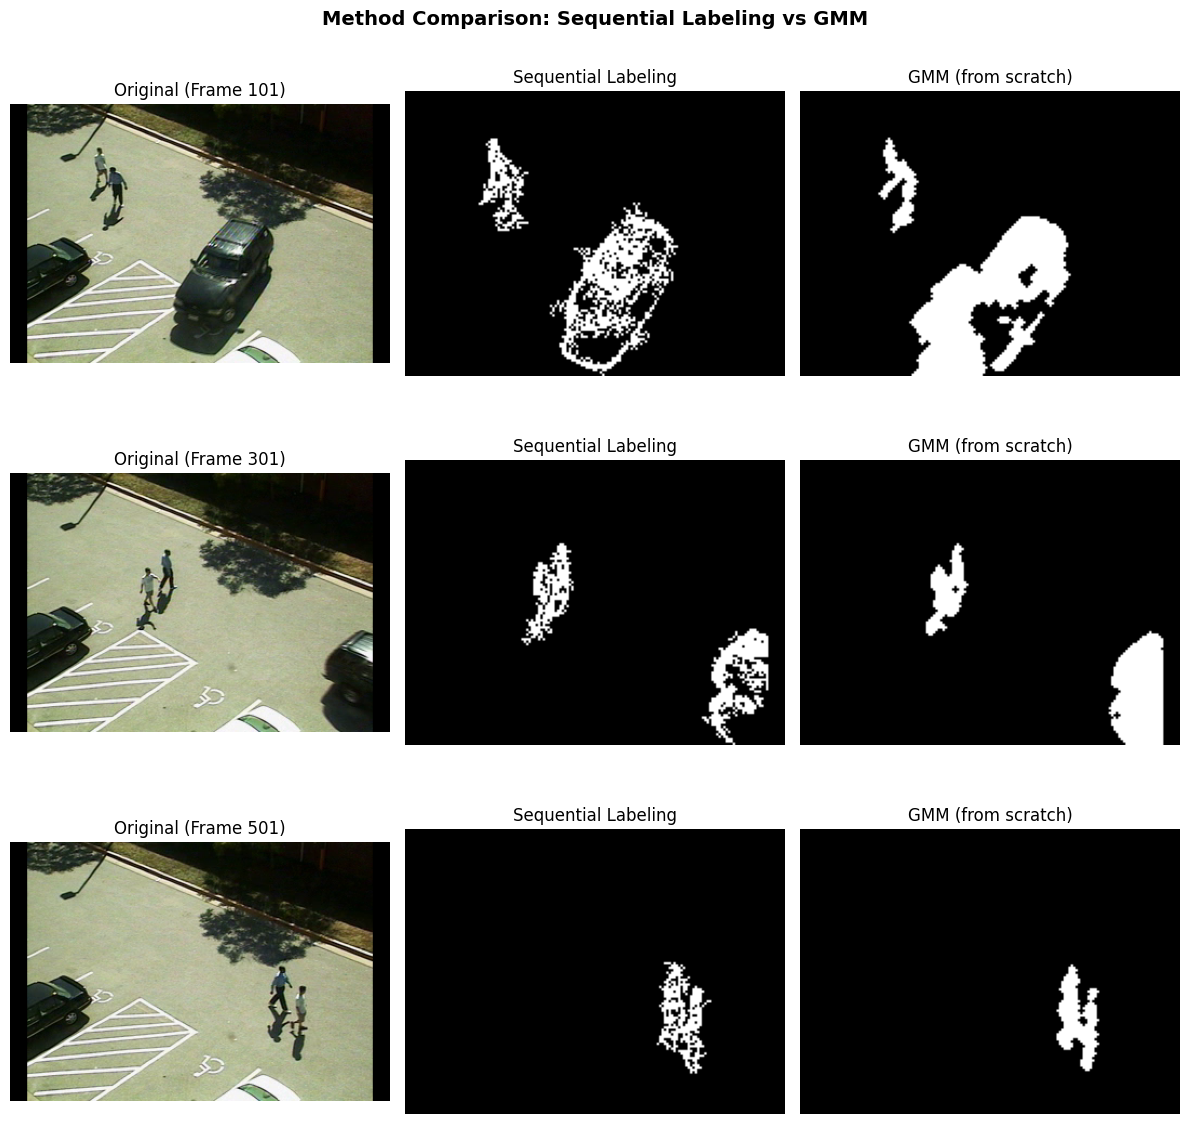

In [209]:
print("\n" + "="*80)
print("COMPARING TWO METHODS")
print("="*80)

# Visualize comparison
sample_frames_idx = [100, 300, 500]

fig, axes = plt.subplots(len(sample_frames_idx), 3, figsize=(12, 12))

for row, idx in enumerate(sample_frames_idx):
    # Original
    axes[row, 0].imshow(cv2.cvtColor(frames[idx+1], cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title(f'Original (Frame {idx+1})')
    axes[row, 0].axis('off')
    
    # Sequential Labeling
    axes[row, 1].imshow(masks_seq[idx], cmap='gray')
    axes[row, 1].set_title('Sequential Labeling')
    axes[row, 1].axis('off')
    
    # GMM
    axes[row, 2].imshow(masks_gmm[idx], cmap='gray')
    axes[row, 2].set_title('GMM (from scratch)')
    axes[row, 2].axis('off')

plt.suptitle('Method Comparison: Sequential Labeling vs GMM', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [210]:
# ============================================================================
# CELL 8: EXTRACT FOREGROUND AND BACKGROUND FRAMES
# ============================================================================

print("\n" + "="*80)
print("STEP 7: EXTRACTING FOREGROUND AND BACKGROUND FRAMES")
print("="*80)

# Choose method (Sequential Labeling as primary)
chosen_masks = masks_seq
method_name = "Sequential Labeling"

print(f"Using {method_name} masks")

# Resize masks back to original size
masks_full = []
for mask in chosen_masks:
    mask_full = cv2.resize(mask, (width, height), interpolation=cv2.INTER_NEAREST)
    masks_full.append(mask_full)

# Extract foreground and background
foreground_frames = []
background_frames = []

print("Extracting foreground and background...")
for i in range(len(masks_full)):
    frame = frames[i+1]  # +1 because motion starts from frame 1
    mask = masks_full[i]
    
    # Foreground: F^fg = F ⊙ M
    fg = cv2.bitwise_and(frame, frame, mask=mask)
    foreground_frames.append(fg)
    
    # Background: F^bg = F ⊙ (1 - M)
    mask_inv = cv2.bitwise_not(mask)
    bg = cv2.bitwise_and(frame, frame, mask=mask_inv)
    background_frames.append(bg)
    
    if (i+1) % 100 == 0:
        print(f"  Extracted {i+1}/{len(masks_full)} frames")

print(f"\n✓ Extraction complete")
print(f"  Foreground frames: {len(foreground_frames)}")
print(f"  Background frames: {len(background_frames)}")


STEP 7: EXTRACTING FOREGROUND AND BACKGROUND FRAMES
Using Sequential Labeling masks
Extracting foreground and background...
  Extracted 100/998 frames
  Extracted 200/998 frames
  Extracted 300/998 frames
  Extracted 400/998 frames
  Extracted 500/998 frames
  Extracted 600/998 frames
  Extracted 700/998 frames
  Extracted 800/998 frames
  Extracted 900/998 frames

✓ Extraction complete
  Foreground frames: 998
  Background frames: 998


In [213]:
# ============================================================================
# GENERATE GMM VIDEOS
# ============================================================================

print("\n" + "="*80)
print("GENERATING GMM FOREGROUND AND BACKGROUND VIDEOS")
print("="*80)

# Extract foreground and background frames using GMM masks
foreground_frames_gmm = []
background_frames_gmm = []

print("\nExtracting foreground and background with GMM masks...")
for i, mask in enumerate(masks_gmm):
    # Resize mask to original frame size
    mask_resized = cv2.resize(mask, (width, height))
    
    # Convert to 3-channel
    mask_3ch = cv2.cvtColor(mask_resized, cv2.COLOR_GRAY2BGR)
    
    # Extract foreground: original frame AND mask
    foreground = cv2.bitwise_and(frames[i+1], mask_3ch)
    
    # Extract background: original frame AND inverted mask
    background = cv2.bitwise_and(frames[i+1], cv2.bitwise_not(mask_3ch))
    
    foreground_frames_gmm.append(foreground)
    background_frames_gmm.append(background)
    
    if (i+1) % 100 == 0:
        print(f"  Processed {i+1}/{len(masks_gmm)} frames")

print(f"✓ Extracted {len(foreground_frames_gmm)} foreground frames")
print(f"✓ Extracted {len(background_frames_gmm)} background frames")

# Save GMM foreground video
foreground_gmm_path = os.path.join(output_dir, 'foreground_gmm.mp4')
print(f"\nSaving GMM foreground video: {foreground_gmm_path}")

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out_fg = cv2.VideoWriter(foreground_gmm_path, fourcc, fps, (width, height))

for frame in foreground_frames_gmm:
    out_fg.write(frame)

out_fg.release()
print("✓ GMM foreground video saved")

# Save GMM background video
background_gmm_path = os.path.join(output_dir, 'background_gmm.mp4')
print(f"\nSaving GMM background video: {background_gmm_path}")

out_bg = cv2.VideoWriter(background_gmm_path, fourcc, fps, (width, height))

for frame in background_frames_gmm:
    out_bg.write(frame)

out_bg.release()
print("✓ GMM background video saved")

print("\n" + "="*80)
print("GMM VIDEO GENERATION COMPLETE")
print("="*80)
print(f"Files created:")
print(f"  - {foreground_gmm_path}")
print(f"  - {background_gmm_path}")


GENERATING GMM FOREGROUND AND BACKGROUND VIDEOS

Extracting foreground and background with GMM masks...
  Processed 100/998 frames
  Processed 200/998 frames
  Processed 300/998 frames
  Processed 400/998 frames
  Processed 500/998 frames
  Processed 600/998 frames
  Processed 700/998 frames
  Processed 800/998 frames
  Processed 900/998 frames
✓ Extracted 998 foreground frames
✓ Extracted 998 background frames

Saving GMM foreground video: C:\Users\Jyotirmoy Nath\Downloads\Assignment1\foreground_gmm.mp4
✓ GMM foreground video saved

Saving GMM background video: C:\Users\Jyotirmoy Nath\Downloads\Assignment1\background_gmm.mp4
✓ GMM background video saved

GMM VIDEO GENERATION COMPLETE
Files created:
  - C:\Users\Jyotirmoy Nath\Downloads\Assignment1\foreground_gmm.mp4
  - C:\Users\Jyotirmoy Nath\Downloads\Assignment1\background_gmm.mp4


In [211]:

# ============================================================================
# CELL 9: WRITE TWO VIDEOS
# ============================================================================

print("\n" + "="*80)
print("STEP 8: WRITING VIDEOS")
print("="*80)

output_dir = r'C:\Users\Jyotirmoy Nath\Downloads\Assignment1'
fourcc = cv2.VideoWriter_fourcc(*'mp4v')

# Write foreground video
fg_video_path = os.path.join(output_dir, 'foreground.mp4')
out = cv2.VideoWriter(fg_video_path, fourcc, fps, (width, height))

print("Writing foreground video...")
for fg_frame in foreground_frames:
    out.write(fg_frame)
out.release()
print(f"✓ Foreground video saved: foreground.mp4")

# Write background video
bg_video_path = os.path.join(output_dir, 'background.mp4')
out = cv2.VideoWriter(bg_video_path, fourcc, fps, (width, height))

print("Writing background video...")
for bg_frame in background_frames:
    out.write(bg_frame)
out.release()
print(f"✓ Background video saved: background.mp4")


STEP 8: WRITING VIDEOS
Writing foreground video...
✓ Foreground video saved: foreground.mp4
Writing background video...
✓ Background video saved: background.mp4


In [212]:
params_path = os.path.join(output_dir, 'parameters.txt')

params_content = f"""
================================================================================
BACKGROUND SUBTRACTION - PARAMETERS
================================================================================

VIDEO: {os.path.basename(video_path)}
- Resolution: {width} × {height}
- FPS: {fps:.2f}
- Total frames: {len(frames)}

PREPROCESSING:
- Grayscale conversion
- Resized to: {RESIZE_WIDTH} × {RESIZE_HEIGHT}

MOTION ESTIMATION:
- Method: Frame difference D_t = |F_t - F_{t-1}|

================================================================================
METHOD 1: SEQUENTIAL LABELING
================================================================================

Parameters:
- Threshold (τ): 2.2
- Minimum blob area: 50 pixels
- Connectivity: 8-connected
- Morphological operations: None

Implementation:
- Threshold motion values
- Connected components labeling
- Filter regions < 50 pixels
- Coded from scratch

================================================================================
METHOD 2: GAUSSIAN MIXTURE MODEL (GMM)
================================================================================

Parameters:
- Gaussians per pixel (K): 3
- Learning rate (α): 0.01
- Match threshold: 2.5σ
- Background ratio (T): 0.7
- Initial variance: 15

Implementation:
- Multi-Gaussian per pixel
- Online weight/mean/variance updates
- Fitness-based sorting (w/σ)
- Coded from scratch

================================================================================
OUTPUT FILES
================================================================================

foreground.mp4 - Moving objects only
background.mp4 - Static background only
parameters.txt - This file

================================================================================
CODE IMPLEMENTATION
================================================================================

Libraries:
- OpenCV: Video I/O, connected components
- NumPy: Array operations

NOT used:
- cv2.BackgroundSubtractorMOG2
- cv2.BackgroundSubtractorKNN
- sklearn (any module)

Generated: {np.datetime64('today')}
================================================================================
"""

with open(params_path, 'w', encoding='utf-8') as f:
    f.write(params_content)

print(f"✓ Parameters saved: parameters.txt")

✓ Parameters saved: parameters.txt
